## Data Manipulation


In [1]:
import seaborn as sns

In [ ]:
# Display all available datasets in seaborn
sns.get_dataset_names()


In [66]:
# Load the Titanic dataset
df = sns.load_dataset('titanic')

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [68]:
# menambahkan baris baru
df.tail()
df.loc[893] = df.loc[0]  # Menyalin baris pertama ke baris baru dengan index 891

In [69]:
df.reset_index(drop=True, inplace=True)  # Mengatur ulang index dan menghapus index lama

In [70]:
df.tail()
len(df)

892

In [71]:
df['who'].unique()
#df.drop(df[df['who'] == 'child'].index, inplace=True) # menghapus baris dengan nilai 'child' pada kolom 'who'

<StringArray>
['man', 'woman', 'child']
Length: 3, dtype: str

In [72]:
df.head()
df.tail()
import pandas as pd # mengimpor library pandas
pd.concat([df.head(), df.tail()]) # menggabungkan 5 baris pertama dan 5 baris terakhir dari DataFrame df



,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True
891,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False


In [73]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True
891,0,3,male,22.0,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False


## Handling Missing Value
1. drop -> terlalu banyak, effort lebih
2. imputasi -> mean, median, modus, interpolasi

In [90]:
df.isnull().sum() # menghitung jumlah nilai null pada setiap kolom
df.drop(columns='deck', inplace=True) # menghapus kolom 'deck' dari DataFrame df
df[df['embark_town'].isnull()] # menampilkan baris dengan nilai null pada kolom 'embark_town'


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone


In [91]:
# groupby, untuk mengatasi data yang hilang kita harus punya dasar sebagaimananya case diatas
df.groupby(['class','embark_town'])['fare'].mean() # menghitung rata-rata fare berdasarkan class dan embark_town southampton

class   embark_town
First   Cherbourg      104.718529
        Queenstown      90.000000
        Southampton     70.514244
Second  Cherbourg       25.358335
        Queenstown      12.350000
        Southampton     20.327439
Third   Cherbourg       11.214083
        Queenstown      11.183393
        Southampton     14.623196
Name: fare, dtype: float64

In [92]:
# imputasi -> mengisi nilai null dengan nilai yang lebih representatif
df['embark_town'] = df['embark_town'].fillna('Southampton') # mengisi nilai null pada kolom 'embark_town' dengan 'Southampton'
df['embarked'] = df['embarked'].fillna('S') # mengisi nilai null pada kolom 'embarked' dengan 'S'

In [93]:
df.sample(1) # mengecek data kosong usia
df['who'].unique() # mengecek data kosong usia
df[df['age'].isnull()] # menampilkan baris dengan nilai null pada kolom 'age'
df[df['age'].isnull()]['who'].unique() # menampilkan baris dengan nilai null pada kolom 'age'

df.groupby('who')['age'].mean() # menghitung rata-rata usia berdasarkan kolom 'who'

who
child     6.369518
man      33.112454
woman    32.000000
Name: age, dtype: float64

In [94]:
# 33 if who == man and age.isnull elif 32 if who == woman and age.isnull else age

df['age'] = df.apply(lambda x:  33 if x['who'] == 'man' and pd.isnull(x['age']) else (32 if x['who'] == 'woman' and pd.isnull(x['age']) else x['age']), axis=1)

df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,32.0,1,2,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,Queenstown,no,True


In [95]:
df.isnull().sum() # menghitung jumlah nilai null pada setiap kolom

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

## Handling Outliers

Nilai ekstrim, anomali
1. iqr
2. std

upper bound: 54.5
lower bound: 2.5


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,32.0,1,2,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,Queenstown,no,True


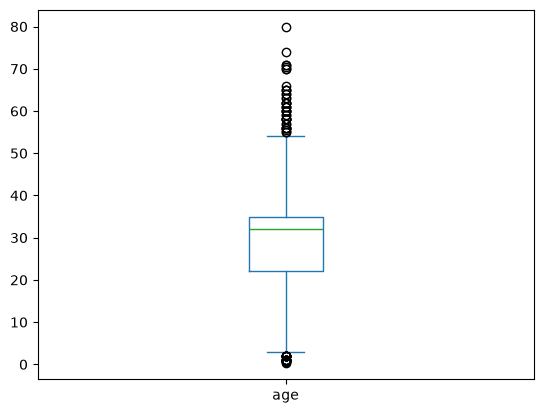

In [98]:
df['age'].plot.box() # membuat boxplot untuk kolom 'age'

# iqr
q1 = df['age'].quantile(0.25) # menghitung kuartil pertama (Q1) untuk kolom 'age', boleh ditulis .25
q3 = df['age'].quantile(0.75) # menghitung kuartil ketiga (Q3) untuk kolom 'age', boleh ditulis .75
iqr = q3 - q1 # menghitung interquartile range (IQR)

# Digunakan saat kita mau memfilter
print(f'upper bound: {q3 + 1.5 * iqr}') # menghitung batas atas untuk mendeteksi outlier
print(f'lower bound: {q1 - 1.5 * iqr}') # menghitung batas bawah untuk mendeteksi outlier

df[df['age'] <  2.5] # menampilkan baris dengan nilai 'age' yang lebih besar dari batas atas (outlier)

df.drop(df[df['age'] <  2.5].index) # menghapus baris dengan nilai 'age' yang lebih besar dari batas atas (outlier), tidak benar-benar dihapus



## EDA (Exploratory Data Analysis)
groupby + aggregation

In [99]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,32.0,1,2,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,Queenstown,no,True


### EDA tujuan untuk ekspolarasi data, data analis hanya sampai disini dan menggambarkan melalui visualisasi, sedangkan proses selanjutnya dikerjakan data scientist

<Axes: ylabel='Frequency'>

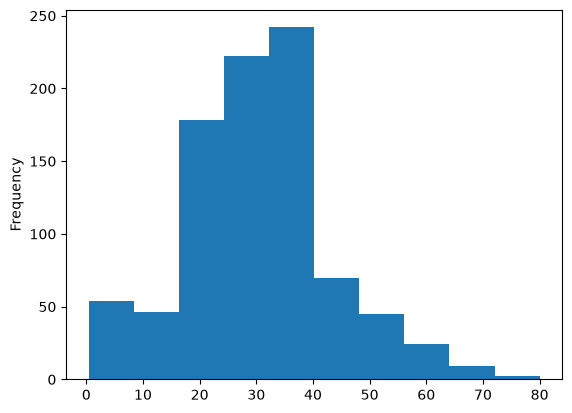

In [135]:
# df.groupby('sex')['age'].mean().plot.bar() # menghitung rata-rata usia berdasarkan kolom 'sex'

df.groupby('embark_town')['fare'].agg(['mean', 'max']) # menghitung rata-rata dan nilai maksimum fare berdasarkan embark_town

df.groupby('embark_town').agg({'age':'mean', 'fare':'median'}) # menghitung rata-rata usia dan median fare berdasarkan embark_town

df['age'].plot.hist() # membuat histogram untuk kolom 'age'




In [ ]:
import matplotlib.pyplot as plt # mengimpor library matplotlib.pyplot berfungsi untuk membuat visualisasi data

C:\Users\SITP\AppData\Local\Temp\ipykernel_21052\2509393633.py:5: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.scatterplot(data=df, x=df['age'], y=df['fare'], hue=df['sex'], palette=sns.husl_palette()) # membuat scatter plot antara kolom 'age' dan 'fare' dengan warna berdasarkan kolom 'sex'


<Axes: xlabel='age', ylabel='fare'>

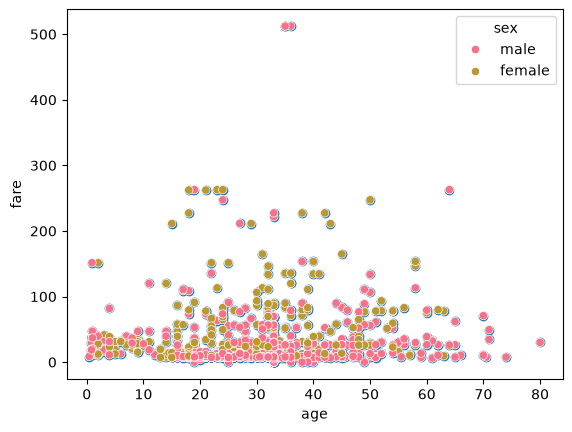

In [108]:
plt.scatter(df['age'], df['fare']) # membuat scatter plot antara kolom 'age' dan 'fare'

df['age'].corr(df['fare']) # menghitung korelasi antara kolom 'age' dan 'fare'

sns.scatterplot(data=df, x=df['age'], y=df['fare'], hue=df['sex'], palette=sns.husl_palette()) # membuat scatter plot antara kolom 'age' dan 'fare' dengan warna berdasarkan kolom 'sex' 



<Axes: xlabel='age', ylabel='Count'>

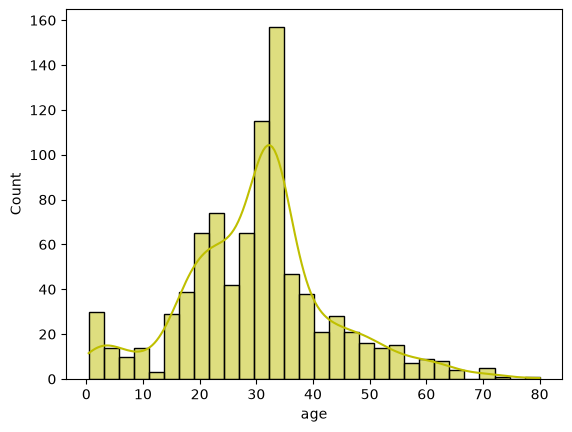

In [110]:
sns.histplot(data=df, x=df['age'], color='y', kde=True) # membuat histogram untuk kolom 'age' dengan warna kuning, menampilkan kurva kepadatan (kde)

### Mengatur Canvas agar bisa menampilkan beberapa visual


C:\Users\SITP\AppData\Local\Temp\ipykernel_21052\1097865267.py:10: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.scatterplot(data=df, x=df['age'], y=df['fare'], hue=df['sex'], palette=sns.husl_palette(), ax=axes[1])


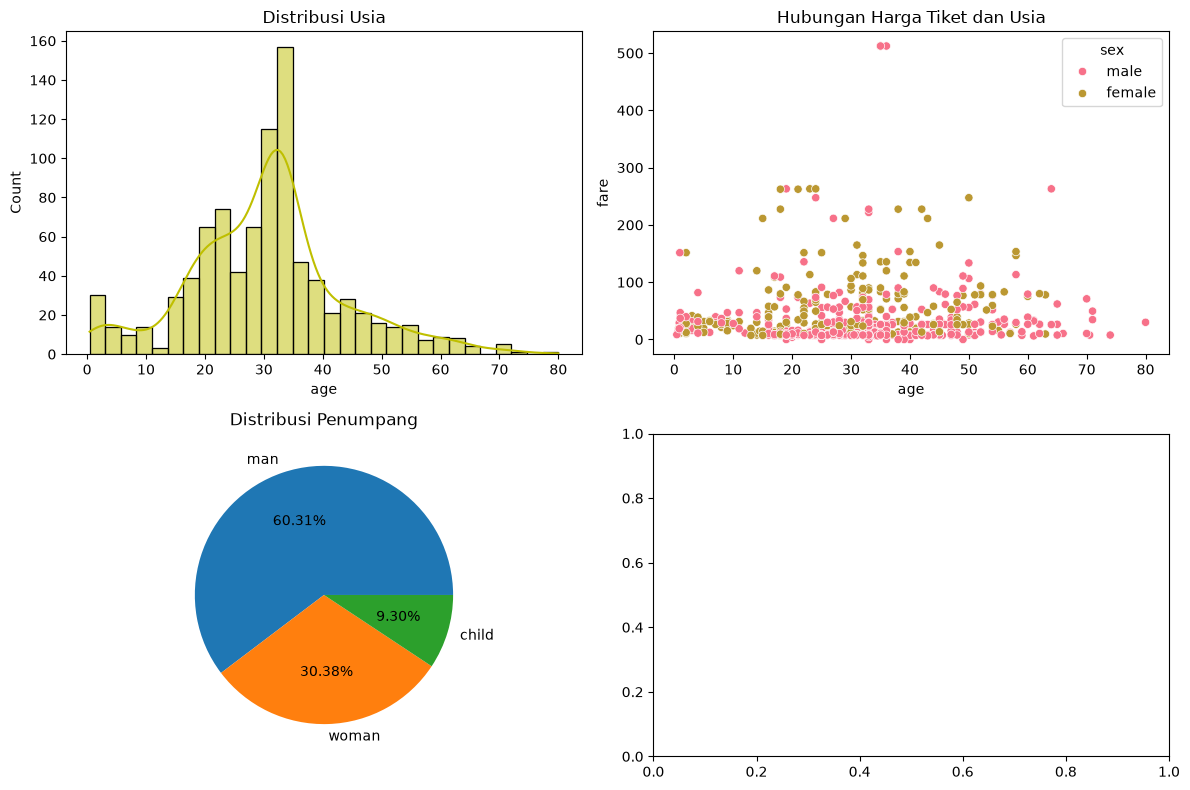

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(12,8)) # membuat subplots dengan 2 baris dan 2 kolom, ukuran figure 12x8

axes = axes.flatten() # meratakan array axes menjadi 1 dimensi

# visual 1
sns.histplot(data=df, x=df['age'], color='y', kde=True, ax=axes[0]) 
axes[0].set_title('Distribusi Usia') # memberikan judul pada subplot pertama

# visual 2
sns.scatterplot(data=df, x=df['age'], y=df['fare'], hue=df['sex'], palette=sns.husl_palette(), ax=axes[1]) 
axes[1].set_title('Hubungan Harga Tiket dan Usia') # memberikan judul pada subplot kedua

# visual 3
axes[2].pie(df['who'].value_counts().values, labels=df['who'].value_counts().index, autopct='%1.2f%%') # membuat pie chart untuk kolom 'who'
axes[2].set_title('Distribusi Penumpang') # memberikan judul pada subplot ketiga

plt.tight_layout() # menyesuaikan layout agar tidak saling tumpang tindih

plt.savefig('visualisasi.png') # menyimpan figure sebagai file 'visualisasi.png'


In [ ]:
df['who'].value_counts().index